# Gym demo

Demonstrate the use of the the Gym interface

In [12]:
%matplotlib inline

import matplotlib.pyplot as plt
import sys
import os
import numpy as np
import pandas as pd
import glob as glob
import time
import pickle
from omegaconf import OmegaConf

# add custom paths
sys.path.extend([os.path.abspath('./assetto_corsa_gym')])
import AssettoCorsaEnv.assettoCorsa as assettoCorsa

# Configure the logging system
import logging
logger = logging.getLogger(__name__)
logging.basicConfig(
    level=logging.INFO,  # Set the logging level (DEBUG, INFO, WARNING, ERROR, CRITICAL)
    format='%(asctime)s - %(name)s - %(levelname)s - %(message)s',  # Format of the log messages
    datefmt='%Y-%m-%d %H:%M:%S',  # Format of the timestamp
)



## Load config file

In [13]:
config = OmegaConf.load("config.yml")

# Create env object

In [14]:
env = assettoCorsa.make_ac_env(cfg=config, work_dir="output")


INFO:AssettoCorsaEnv.ac_env:Setting track ks_barcelona-layout_gp
INFO:AssettoCorsaEnv.track:Track loaded from: C:\Users\rhysi\Documents\Projects\Masters Project\assetto_corsa_gym\assetto_corsa_gym\AssettoCorsaEnv\../AssettoCorsaConfigs\tracks\ks_barcelona-layout_gp.csv Found 3000 segments downsampled by 10= 300 segments
INFO:AssettoCorsaEnv.reference_lap:Reference Lap. Loading: C:\Users\rhysi\Documents\Projects\Masters Project\assetto_corsa_gym\assetto_corsa_gym\AssettoCorsaEnv\../AssettoCorsaConfigs\tracks\ks_barcelona-layout_gp-racing_line_fixed.csv
INFO:AssettoCorsaEnv.reference_lap:Using curvature from racing line file
INFO:AssettoCorsaEnv.sensors_ray_casting:spatial_hash len 109
C:\Users\rhysi\Downloads\Anaconda\envs\p309\lib\site-packages\gym\spaces\box.py:73: UserWarning: WARN: Box bound precision lowered by casting to float32
  logger.warn(
INFO:AssettoCorsaEnv.ac_env:Adding previous obs to state 25*3 = 100
INFO:AssettoCorsaEnv.ac_env:state_dim 125
INFO:AssettoCorsaEnv.ac_env:a

# Show static info

In [15]:
static_info = env.client.simulation_management.get_static_info()
ac_mod_config = env.client.simulation_management.get_config()

logger.info("Static info:")
for i in static_info:
    logger.info(f"{i}: {static_info[i]}")
logger.info("AC Mod config:")
for i in ac_mod_config:
    logger.info(f"{i}: {ac_mod_config[i]}")


INFO:__main__:Static info:
INFO:__main__:WindSpeed: 0
INFO:__main__:TyreContactPoint_RL: [170.65818786621094, 2.1704463958740234, -538.1796875]
INFO:__main__:TyreContactPoint_FR: [173.8168487548828, 2.096771240234375, -538.7320556640625]
INFO:__main__:CAR_WHEEL_R: [0.26899999380111694, 0.26899999380111694, 0.2784999907016754, 0.2784999907016754]
INFO:__main__:isCarInPitlane: 0
INFO:__main__:TyreContactPoint_FL: [172.80946350097656, 2.1256895065307617, -539.9696655273438]
INFO:__main__:CarName: dallara_f317
INFO:__main__:CAR_TRACK: 1.5415952582821255
INFO:__main__:CAR_WHEELBASE: 2.798930398250973
INFO:__main__:isCarInPit: 0
INFO:__main__:LastSplits: [0, 0, 0]
INFO:__main__:penaltiesEnabled: 1
INFO:__main__:TrackConfiguration: layout_gp
INFO:__main__:TyreContactPoint_RR: [171.6313018798828, 2.1450068950653076, -536.9843139648438]
INFO:__main__:autoShifterOn: 1
INFO:__main__:TrackLength: 4591.88720703125
INFO:__main__:WorldPosition: [172.03994750976562, 2.424879550933838, -538.30651855468

# Apply actions and recover the car

In [16]:
states = []

env.reset()

actions = np.array([0.1, 0.5, -1.0])

for i in range(200):
    if i % 2 == 0:
        steer = .1
    else:
        steer = -.1
    env.set_actions(np.array([steer, 0.5, -1.0]))
    next_state, reward, done, info = env.step(action=None)  # action is already applied
    
    if done:
        break

env.recover_car()
env.close()

INFO:AssettoCorsaEnv.ac_env:Reset AC. Episode 1 total_steps: 0
INFO:AssettoCorsaEnv.ac_client:sending reset to simulation management server
INFO:AssettoCorsaEnv.ac_client:AC Client. Listening at host: localhost port: 2345
INFO:AssettoCorsaEnv.ac_client:Client connected on 2345
INFO:AssettoCorsaEnv.ac_env:Recover car
INFO:AssettoCorsaEnv.ac_client:sending reset to simulation management server
INFO:AssettoCorsaEnv.ac_env:Saved raw data to: output\laps\/20261021_233107.604_states.parquet
INFO:AssettoCorsaEnv.ac_env:total_steps: 203 ep_steps: 200 ep_reward:    0.0 LapDist: 3871.48 packages lost 0 BestLap: 0.0
INFO:AssettoCorsaEnv.ac_env:LapNo_0:   0.00
INFO:AssettoCorsaEnv.ac_env:ep_bestLapTime:   0.00
INFO:AssettoCorsaEnv.ac_env:speed_mean:   0.00 speed_max:   0.02 max_abs_gap:   0.02 ep_laps: 1
INFO:AssettoCorsaEnv.ac_env:dt avr: 0.040 std: 0.001 min: 0.039 max: 0.042


{'ep_count': 1,
 'ep_steps': 201,
 'total_steps': 203,
 'packages_lost': 0,
 'ep_reward': 0.0017275258699638485,
 'speed_mean': 0.0007175121724834916,
 'speed_max': 0.019434796646237373,
 'BestLap': 0.0,
 'terminated': False,
 'LapNo_0': 0.0,
 'ep_bestLapTime': 0}

In [23]:
import cv2
import mss
import numpy as np
import pygetwindow as gw
import matplotlib.pyplot as plt


class DirectWindowGrabber:
    """Bypasses AssettoCorsaGym's shared-memory dual_buffer by grabbing

    the 'Assetto Corsa' window directly from Windows desktop memory.
    """

    def __init__(
        self,
        window_title: str = "Assetto Corsa",
        target_width: int = 320,
        target_height: int = 240,
    ):
        self.window_title = window_title
        self.target_width = target_width
        self.target_height = target_height
        self.sct = mss.mss()
        self.win = self._find_window()

    def _find_window(self):
        windows = gw.getWindowsWithTitle(self.window_title)
        for w in windows:
            # Match the actual game simulator window (avoiding Content Manager or folders)
            if w.title.strip() == "Assetto Corsa" or "Assetto Corsa" in w.title:
                if w.width > 100 and w.height > 100:
                    return w
        raise RuntimeError(
            f"Could not find running window titled '{self.window_title}'. "
            "Make sure Assetto Corsa is on track in Windowed mode!"
        )

    def grab_bgr(self) -> np.ndarray:
        """Captures the AC window and returns a (target_height, target_width, 3) BGR array."""
        # Crop out the Windows title bar (top 31px) and window border (8px left/right)
        monitor = {
            "top": self.win.top + 31,
            "left": self.win.left + 8,
            "width": max(1, self.win.width - 16),
            "height": max(1, self.win.height - 39),
        }
        sct_img = self.sct.grab(monitor)
        # mss returns BGRA; slice [:, :, :3] for standard 3-channel BGR
        img_bgr = np.array(sct_img)[:, :, :3]
        img_bgr = cv2.resize(
            img_bgr,
            (self.target_width, self.target_height),
            interpolation=cv2.INTER_AREA,
        )
        return img_bgr

C:\Users\rhysi\AppData\Local\Temp\ipykernel_33872\2476054200.py:23: DeprecationWarning: mss.mss is deprecated and will be removed in a future release; use mss.MSS instead
  self.sct = mss.mss()
INFO:AssettoCorsaEnv.ac_env:Reset AC. Episode 2 total_steps: 203
INFO:AssettoCorsaEnv.ac_client:sending reset to simulation management server
INFO:AssettoCorsaEnv.ac_client:AC Client. Listening at host: localhost port: 2345
INFO:AssettoCorsaEnv.ac_client:Client connected on 2345


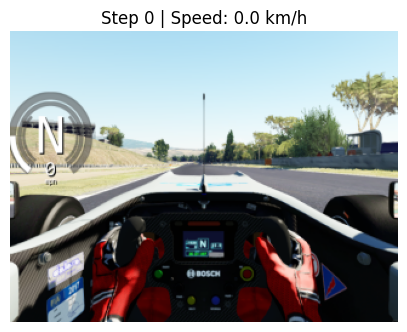

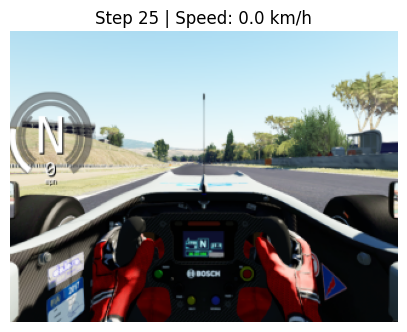

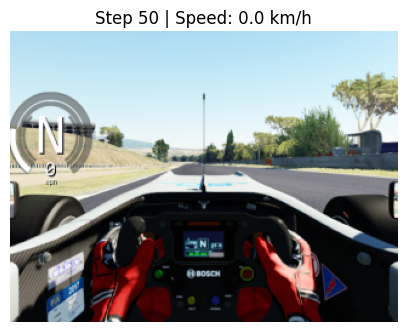

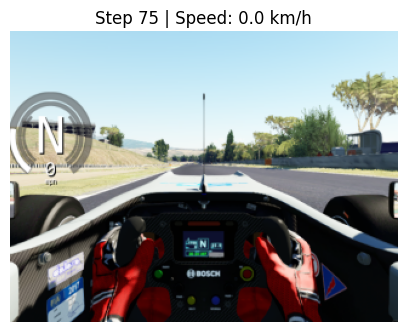

INFO:AssettoCorsaEnv.ac_env:Recover car
INFO:AssettoCorsaEnv.ac_client:sending reset to simulation management server


In [24]:
grabber = DirectWindowGrabber(target_width=320, target_height=240)

env.reset()

for i in range(100):
    steer = 0.1 if (i % 2 == 0) else -0.1
    # Pass 0.5 for throttle so relative actions quickly press the gas pedal
    env.client.respond_to_server()
    action = np.array([steer, 0.5, -1.0])
    next_state, reward, done, info = env.step(action)

    # Every 25 steps (once per second), grab and display the live game frame!
    if i % 25 == 0:
        frame_bgr = grabber.grab_bgr()
        plt.figure(figsize=(5, 4))
        plt.imshow(cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB))
        plt.title(f"Step {i} | Speed: {env.state['speed']*3.6:.1f} km/h")
        plt.axis("off")
        plt.show()

    if done:
        break

env.recover_car()

In [78]:
# 1. Disable relative actions temporarily so 0.8 means 80% throttle immediately
env.use_relative_actions = False
# 2. Prevent reset() from respawning the car if it's already on track
env.set_reset_state(False)

env.reset()

for i in range(200):
    # Apply 80% throttle (0.6 in [-1, 1] range), no brake (-1.0)
    obs, reward, done, info = env.step(np.array([0.0, 0.8, -1.0]))
    if i % 10 == 0:
        s = env.state
        print(
            f"Step {i:2d} | Gear: {s['actualGear']} (1=N, 2=1st) | "
            f"RPM: {s['RPM']:6.0f} | GasPedal: {s['accStatus']:.2f} | "
            f"BrakePedal: {s['brakeStatus']:.2f} | Speed: {s['speed']*3.6:.1f} km/h"
        )

INFO:AssettoCorsaEnv.ac_env:Saved raw data to: output\laps\/20261021_225227.741_states.parquet
INFO:AssettoCorsaEnv.ac_env:total_steps: 1024 ep_steps: 100 ep_reward:    0.0 LapDist: 3969.62 packages lost 0 BestLap: 0.0
INFO:AssettoCorsaEnv.ac_env:LapNo_0:   0.00
INFO:AssettoCorsaEnv.ac_env:ep_bestLapTime:   0.00
INFO:AssettoCorsaEnv.ac_env:speed_mean:   0.02 speed_max:   0.24 max_abs_gap:   0.01 ep_laps: 1
INFO:AssettoCorsaEnv.ac_env:dt avr: 0.040 std: 0.001 min: 0.039 max: 0.042
INFO:AssettoCorsaEnv.ac_env:Reset AC. Episode 9 total_steps: 1024
INFO:AssettoCorsaEnv.ac_client:AC Client. Listening at host: localhost port: 2345
INFO:AssettoCorsaEnv.ac_client:Client connected on 2345


Step  0 | Gear: 1 (1=N, 2=1st) | RPM:   1700 | GasPedal: 0.00 | BrakePedal: 0.00 | Speed: 0.0 km/h
Step 10 | Gear: 1 (1=N, 2=1st) | RPM:   1703 | GasPedal: 0.00 | BrakePedal: 0.00 | Speed: 0.0 km/h
Step 20 | Gear: 1 (1=N, 2=1st) | RPM:   1702 | GasPedal: 0.00 | BrakePedal: 0.00 | Speed: 0.0 km/h
Step 30 | Gear: 1 (1=N, 2=1st) | RPM:   1701 | GasPedal: 0.00 | BrakePedal: 0.00 | Speed: 0.0 km/h
Step 40 | Gear: 1 (1=N, 2=1st) | RPM:   1700 | GasPedal: 0.00 | BrakePedal: 0.00 | Speed: 0.0 km/h
Step 50 | Gear: 1 (1=N, 2=1st) | RPM:   1700 | GasPedal: 0.00 | BrakePedal: 0.00 | Speed: 0.0 km/h
Step 60 | Gear: 1 (1=N, 2=1st) | RPM:   1700 | GasPedal: 0.00 | BrakePedal: 0.00 | Speed: 0.0 km/h
Step 70 | Gear: 1 (1=N, 2=1st) | RPM:   1700 | GasPedal: 0.00 | BrakePedal: 0.00 | Speed: 0.0 km/h
Step 80 | Gear: 1 (1=N, 2=1st) | RPM:   1700 | GasPedal: 0.00 | BrakePedal: 0.00 | Speed: 0.0 km/h
Step 90 | Gear: 1 (1=N, 2=1st) | RPM:   1700 | GasPedal: 0.00 | BrakePedal: 0.00 | Speed: 0.0 km/h
Step 100 |

# Plot states

In [15]:
df = env.get_history()
df.columns

Index(['done', 'SuspensionTravel', 'rr_wheel_load', 'fl_tire_pressure',
       'SlipAngle_fl', 'speed', 'iLastTime', 'accStatus', 'fr_tire_pressure',
       'cgHeight',
       ...
       'going_backwards', 'terminated', 'TimeLimit.truncated',
       'current_action_abs_0', 'current_action_abs_1', 'current_action_abs_2',
       'actions_0', 'actions_1', 'actions_2', 'reward'],
      dtype='object', length=110)

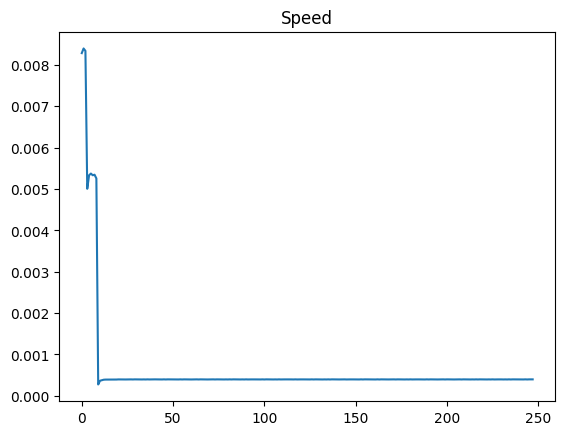

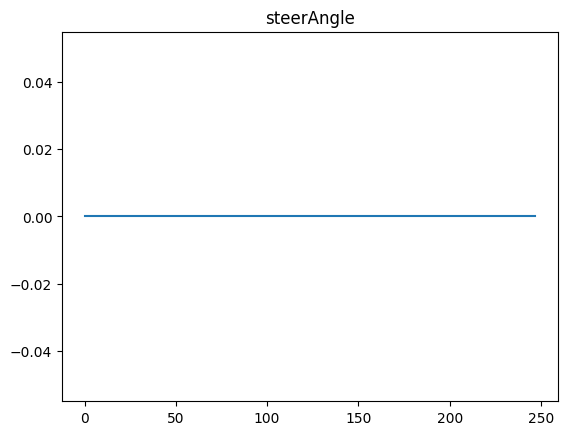

In [16]:
plt.title("Speed")
plt.plot(df.speed)
plt.show()

plt.title("steerAngle")
plt.plot(df.steerAngle)
plt.show()